SpOmiAlign test


In [17]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import cv2
import os
import anndata
import shutil
from PIL import Image
Image.MAX_IMAGE_PIXELS = 665836957
START_DIR = "../../../test/spomialign_test/SPOmiAlign"

PROJECT_ROOT = START_DIR
spomialign_path = PROJECT_ROOT + "/SPOmiAlign"
if str(spomialign_path) not in sys.path:
    sys.path.insert(0, str(spomialign_path))

from tutorial_utils import (
    generate_ssi_visualization,
    get_tutorial_paths,
    run_image_to_image_alignment,
    run_reassignment,
    read_bgr,
)

# DATA_DIR, OUTPUT_ROOT = get_tutorial_paths(PROJECT_ROOT)
DATA_DIR = Path(".")
OUTPUT_ROOT = Path("./results/XeniumR1_vs_HE")
if not os.path.exists(OUTPUT_ROOT):
    os.mkdir(OUTPUT_ROOT)
else:
    shutil.rmtree(OUTPUT_ROOT)
    os.mkdir(OUTPUT_ROOT)
target_image_path= "../../../../ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/HE/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif"
source_image_path= "../../../../ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/Xenium/image_3_rotated.tif"
valid_target_landmarks= "../../../benchmarks/random_landmarks/BreastCancer/HE_vs_XeniumR1/HE_landmarks.csv"
valid_source_landmarks="../../../benchmarks/random_landmarks/BreastCancer/HE_vs_XeniumR1//XeniumR1_landmarks.csv" 
%matplotlib inline

In [18]:
# rotate landmarks
_EXACT = {
    0: None,
    90: Image.Transpose.ROTATE_270,
    180: Image.Transpose.ROTATE_180,
    270: Image.Transpose.ROTATE_90,
}

def rotate_image(image, deg, fill=0):
    key = int(round(deg)) % 360
    if key in _EXACT and abs(deg - round(deg)) < 1e-9:
        op = _EXACT[key]
        return image.copy() if op is None else image.transpose(op)
    return image.rotate(-deg, expand=True, resample=Image.BICUBIC,
                        fillcolor=fill)

def _rotation_matrix(deg):
    radii = np.deg2rad(360 - deg)
    s, c = np.sin(radii), np.cos(radii)
    return np.array([[c, -s], [s, c]])

def rotate_keypoints(xy, deg, image=None):
    points = xy
 
    limits = np.asarray(image.size, dtype=float)          # (width, height)
    origin = limits / 2
 
    image = rotate_image(image, deg)
 
    rotated_limits = np.asarray(image.size, dtype=float)
    rotated_origin = rotated_limits / 2
 
    rotation_mat = _rotation_matrix(deg)

    p = points - origin
    p = p / limits                      # to fractional coordinates
    p = p @ rotation_mat.T
    p = p * rotated_limits              # back to pixels
    p = p + rotated_origin
 
    out = pd.DataFrame({"x": p[:, 0], "y": p[:, 1]})
    out.attrs["image"] = image
    return out

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import anndata as ad

for p in [valid_target_landmarks, valid_source_landmarks]:
    p = Path(p)
    if not p.exists():
        raise FileNotFoundError(f"Landmark file not found: {p}")

def landmark_csv_to_adata(df, spatial_cols=("x", "y")):

    # try common column names for coordinates
    coord_options = [
        ("x", "y"),
        ("X", "Y"),
        ("x_coord", "y_coord"),
        ("xcoord", "ycoord"),
        ("x_px", "y_px"),
    ]
    for cols in coord_options:
        if all(c in df.columns for c in cols):
            spatial_cols = cols
            break

    if not all(c in df.columns for c in spatial_cols):
        raise ValueError(
            f"Could not find spatial coordinate columns. "
            f"Expected one of: {coord_options}"
        )

    # observation names
    if "name" in df.columns:
        obs_names = df["name"].astype(str)
    elif "cell_id" in df.columns:
        obs_names = df["cell_id"].astype(str)
    else:
        obs_names = [f"Cell_{i}" for i in range(len(df))]

    coords = df[list(spatial_cols)].to_numpy(dtype=float)

    adata = ad.AnnData(
        X=np.zeros((len(df), 0)),
        obs=pd.DataFrame(index=pd.Index(obs_names, name="cell_id")),
        obsm={"spatial": coords},
    )
    return adata

valid_source_landmarks_rot = pd.read_csv(valid_source_landmarks)
valid_source_landmarks_rot = np.array(valid_source_landmarks_rot[['x', 'y']])
query_img = Image.open(source_image_path)
valid_source_landmarks_rot[:,1] =  query_img.size[1] - valid_source_landmarks_rot[:,1]
valid_source_landmarks_rot = pd.DataFrame(valid_source_landmarks_rot, columns=["x", "y"])

target_adata = landmark_csv_to_adata(pd.read_csv(valid_target_landmarks))
source_adata = landmark_csv_to_adata(valid_source_landmarks_rot)

# optional: save to disk if you want to pass paths into `PARAMS`
target_h5ad_path = Path(OUTPUT_ROOT) / "target_landmarks.h5ad"
source_h5ad_path = Path(OUTPUT_ROOT) / "source_landmarks.h5ad"

target_adata.write_h5ad(target_h5ad_path)
source_adata.write_h5ad(source_h5ad_path)

Target image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/HE/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif
Source image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/Xenium/image_3_rotated.tif
Target h5ad: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/XeniumR1_vs_HE/target_landmarks.h5ad
Source h5ad: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/XeniumR1_vs_HE/source_landmarks.h5ad
Using device: cpu


2026-11-10 21:58:39.540 | INFO     | romatch.models.model_zoo.roma_models:roma_model:61 - Using coarse resolution (560, 560), and upsample res (864, 1152)


Running RoMa matching...
Estimating affine transform...
Warping images...
Padding fill color: (255, 255, 255)
Processing H5AD coordinates...
[OK] Step 00 source coordinates mapped to render space: 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_00_source_in_render_space.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 02 after resize to registration grid (source resized canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_02_after_resize_to_registration.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 03 after registration transform (target resized canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_03_after_registration_transform.png
[OK] Step 04 after rescale back (target original canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/d

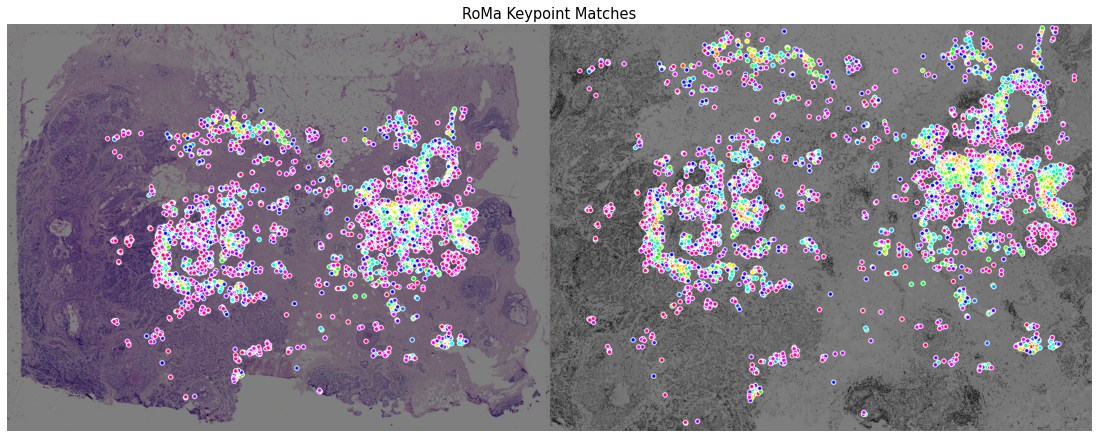

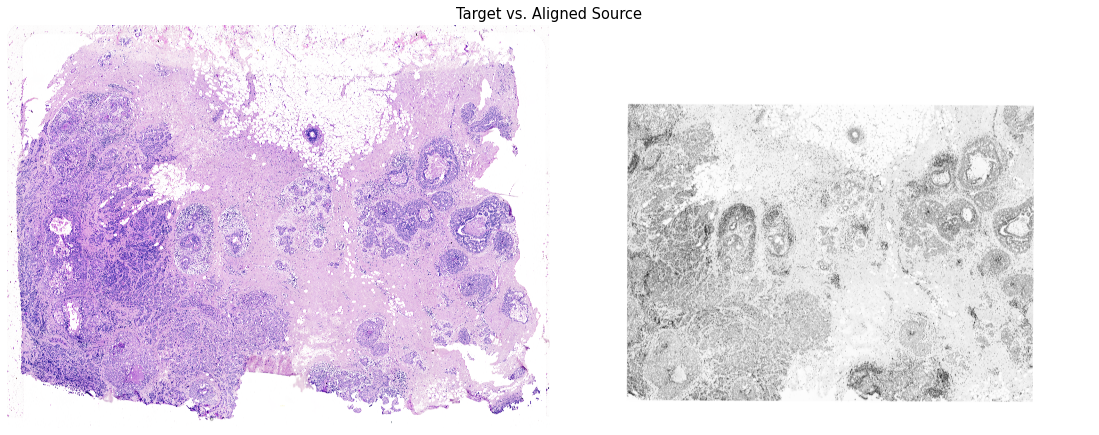

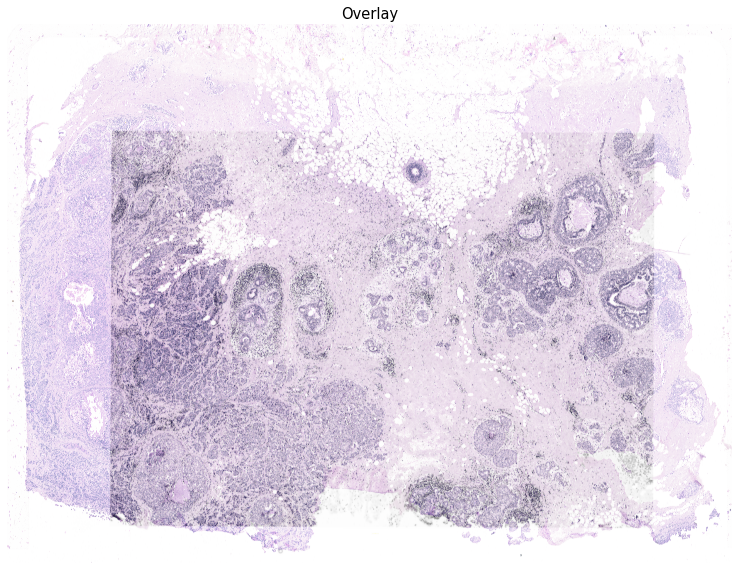

Alignment runtime: 161.9449 seconds
Done. Results saved to results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment


[ WARN:0@1166.841] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1166.841] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


[OK] Scatter PNG saved: results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/target_h5ad_scatter.png (27587x20511, background=black, shape=square, points=60)
[OK] Scatter PNG saved: results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/transformed_h5ad_scatter.png (27587x20511, background=black, shape=square, points=60)


In [20]:
PARAMS = {
    "sample_id": "XeniumtoHE",
    "target_image_path": target_image_path,
    "source_image_path": source_image_path,
    "target_h5ad_path": target_h5ad_path,
    "source_h5ad_path": source_h5ad_path,
    "target_h5ad_spatial_key": "spatial",
    "source_h5ad_spatial_key": "spatial",
    "Alignment_mode": "affine",
    "device": "cpu",
}
PARAMS

result = run_image_to_image_alignment(
    data_root=DATA_DIR,
    output_root=OUTPUT_ROOT,
    **PARAMS,
)

adata = anndata.read_h5ad(result["transformed_h5ad"])
transformed_coords = adata.obsm["spatial"]

Target image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/HE/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif
Source image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/Xenium/image_3_rotated.tif
Target h5ad: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/XeniumR1_vs_HE/target_landmarks.h5ad
Source h5ad: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/XeniumR1_vs_HE/source_landmarks.h5ad
Using device: cpu


2026-11-10 22:03:06.238 | INFO     | romatch.models.model_zoo.roma_models:roma_model:61 - Using coarse resolution (560, 560), and upsample res (864, 1152)


Running RoMa matching...
Estimating affine+bspline transform...
Warping images...
Padding fill color: (255, 255, 255)
Processing H5AD coordinates...
[OK] Step 00 source coordinates mapped to render space: 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_00_source_in_render_space.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 02 after resize to registration grid (source resized canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_02_after_resize_to_registration.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 03 after registration transform (target resized canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/debug_step_03_after_registration_transform.png
[OK] Step 04 after rescale back (target original canvas): 60/60 points inside canvas -> results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/ali

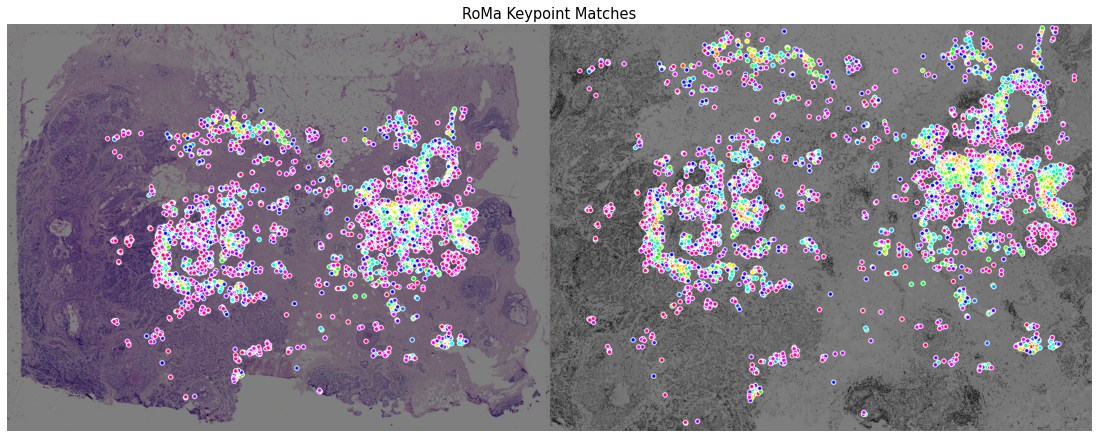

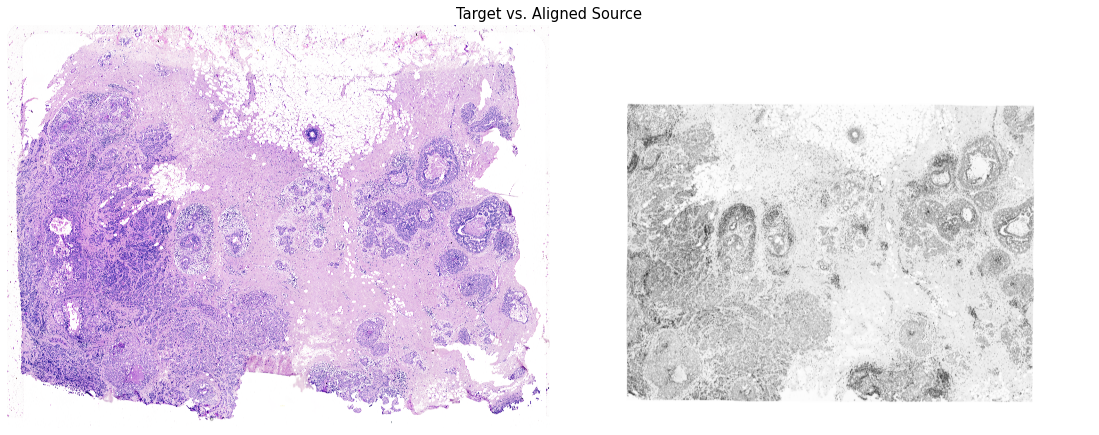

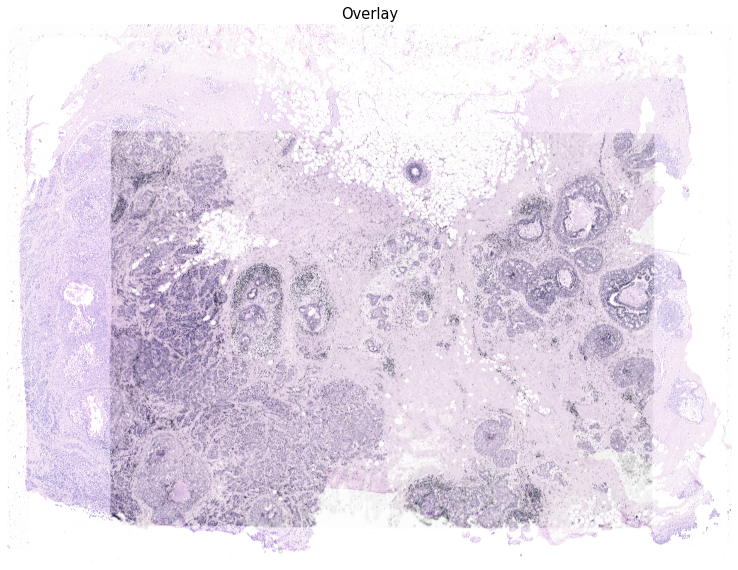

Alignment runtime: 157.2820 seconds
Done. Results saved to results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment


[ WARN:0@1428.448] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1428.448] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


[OK] Scatter PNG saved: results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/target_h5ad_scatter.png (27587x20511, background=black, shape=square, points=60)
[OK] Scatter PNG saved: results/XeniumR1_vs_HE/img_2_img/XeniumtoHE/alignment/transformed_h5ad_scatter.png (27587x20511, background=black, shape=square, points=60)


In [21]:
PARAMS = {
    "sample_id": "XeniumtoHE",
    "target_image_path": target_image_path,
    "source_image_path": source_image_path,
    "target_h5ad_path": target_h5ad_path,
    "source_h5ad_path": source_h5ad_path,
    "target_h5ad_spatial_key": "spatial",
    "source_h5ad_spatial_key": "spatial",
    "Alignment_mode": "affine+bspline",
    "device": "cpu",
}
PARAMS

result = run_image_to_image_alignment(
    data_root=DATA_DIR,
    output_root=OUTPUT_ROOT,
    **PARAMS,
)

adata = anndata.read_h5ad(result["transformed_h5ad"])
transformed_coords_nl = adata.obsm["spatial"]

[2.62455362 3.17206689 1.49851223 4.46877114 0.92424493]
[ 6.40598956 11.19665392  1.88571969  5.06815223 40.31919542]


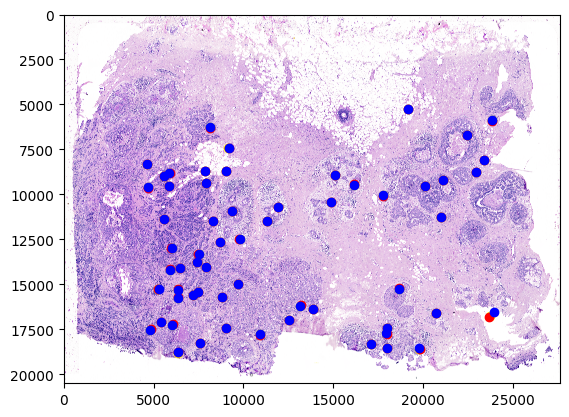

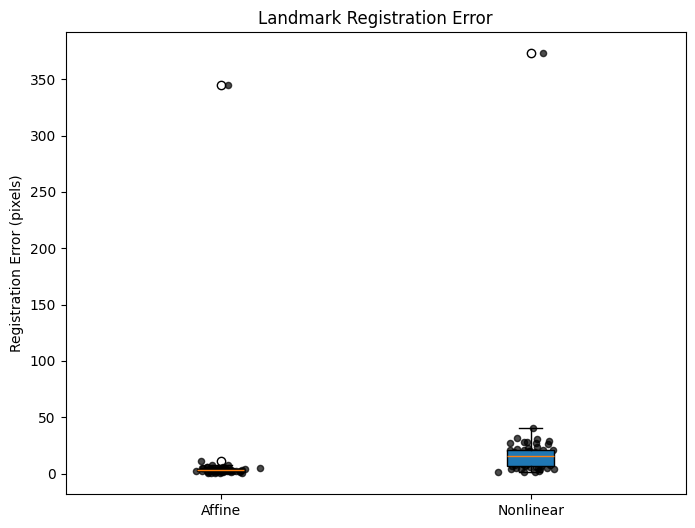

In [24]:
target_coords = target_adata.obsm["spatial"]

# visualize landmarks
fig,ax = plt.subplots()
img = Image.open(target_image_path)
ax.scatter(transformed_coords[:,0], transformed_coords[:,1], alpha=1, c="yellow")
ax.scatter(transformed_coords_nl[:,0], transformed_coords_nl[:,1], alpha=1, c="red")
ax.scatter(target_coords[:,0], target_coords[:,1], alpha=1, c="blue")
ax.imshow(img)

# get distance between landmark and transformation
diff_affine = np.sqrt(np.power(np.array(transformed_coords[:,0])-target_coords[:,0],2) + np.power(np.array(transformed_coords[:,1])-target_coords[:,1],2))
print(diff_affine[:5])
diff_nl = np.sqrt(np.power(np.array(transformed_coords_nl[:,0])-target_coords[:,0],2) + np.power(np.array(transformed_coords_nl[:,1])-target_coords[:,1],2))
print(diff_nl[:5])

# visualize boxplots with points overlaid
fig2, ax2 = plt.subplots(figsize=(8, 6))
data = [diff_affine, diff_nl]
ax2.boxplot(data, labels=['Affine', 'Nonlinear'], patch_artist=True)
# Overlay the points (jittered for visibility)
for i, diff in enumerate(data, start=1):
    ax2.scatter(np.random.normal(i, 0.04, size=len(diff)), diff, alpha=0.7, color='black', s=20)
ax2.set_ylabel('Registration Error (pixels)')
ax2.set_title('Landmark Registration Error')
plt.show()

# save to data
df = pd.DataFrame({
    'x_landmark': target_coords[:,0],
    'y_landmark': target_coords[:,1],
    'x_wsireg_affine': transformed_coords[:,0],
    'y_wsireg_affine': transformed_coords[:,1],
    'x_wsireg_nl': transformed_coords_nl[:,0],
    'y_wsireg_nl': transformed_coords_nl[:,1],
    'diff_affine': diff_affine,
    'diff_nl': diff_nl
})

df.to_csv(str(OUTPUT_ROOT) + "/all_random_landmarks.csv")